# Push detection from video position + IMU

Three steps:
1. **Sync**: shift the IMU in time until its position matches the video position.
2. **Detect pushes in the video**: a push is where the sled stops and turns = a peak of the position `x`.
   Checked against the manual labels.
3. **Check with the IMU**: around each push the sled pauses for a moment. Video and IMU should see the
   same pause; this shows which moment of the pause both measure most consistently.

Everything works in pixels for the video, so the camera position and mm/px scale do not matter.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, find_peaks, savgol_filter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "app"))
from data_analysis import analyse_start, load_imu

WITH_IMU = ["2026-11-19_120403_measurement", "2026-11-19_120443_measurement"]   # video + IMU, no labels
LABELLED = ["2026-11-19_114221_measurement", "2026-11-19_114526_measurement",
            "2026-11-19_114701_measurement"]                                     # video + manual labels, no IMU
FS = 60.0                                                  # common sample rate, Hz
hp_b, hp_a = butter(2, 0.2 / (FS / 2), btype="high")      # 0.2 Hz high-pass: removes IMU drift, keeps the movement

## 1. Sync video and IMU

Per recording:
- video `x` (px, raw marker median) and IMU position (m, from `analyse_start`) on one 60 Hz time grid;
  `imu_offset_s` from `meta.json` (computer clock) is the starting point
- same high-pass on both (removes IMU drift), then z-score (removes px vs m)
- shift the IMU by −0.5…+0.5 s; the shift with the highest correlation r is the correction

,recording,IMU shift (ms),r before,r after
0,2026-11-19_120403_measurement,33,0.993,0.996
1,2026-11-19_120443_measurement,33,0.983,0.985


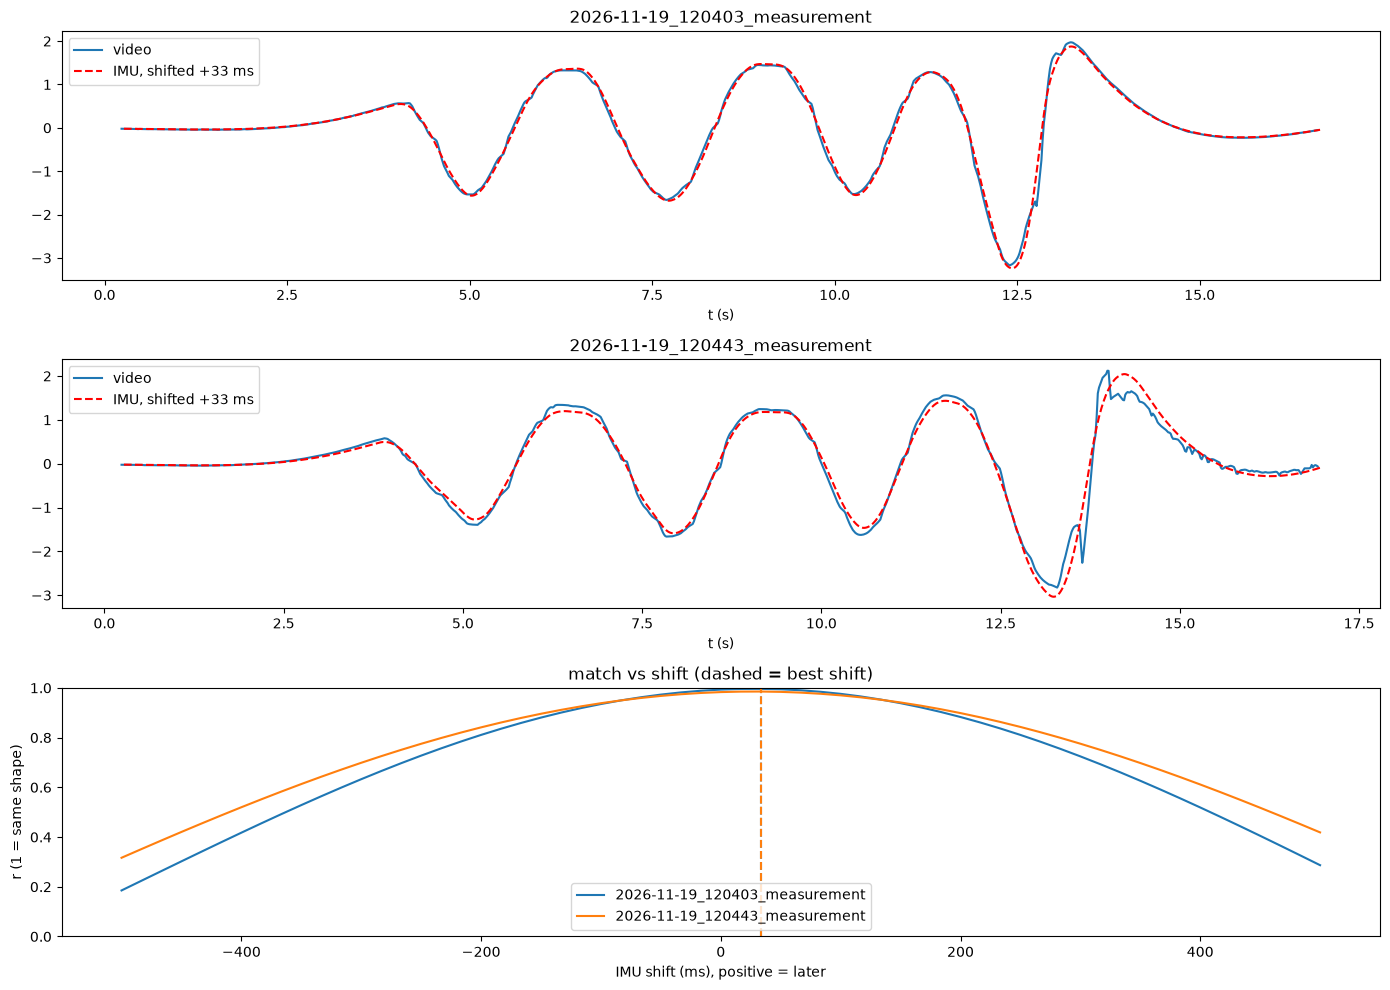

In [2]:
data = {}   # synced (video, imu) per recording, used in step 3
rows = []   # one result row per recording -> table at the end
fig, axes = plt.subplots(3, 1, figsize=(14, 10))   # 2 recordings + the r-vs-shift chart
for ax, name in zip(axes, WITH_IMU):
    folder = ROOT / "analyses" / name
    video = pd.read_csv(folder / "tracking.csv")              # per frame: t (s), x (px, raw marker median)
    imu, _ = analyse_start(load_imu(folder / "imu_raw.csv"))  # IMU chain from the app: t, a, v, x (m)
    imu["t"] += json.loads((folder / "meta.json").read_text())["imu_offset_s"]   # IMU onto video time (computer clock)

    t = np.arange(max(video.t.min(), imu.t.min()), min(video.t.max(), imu.t.max()), 1 / FS)   # common time grid, 60 Hz, where both exist
    v = filtfilt(hp_b, hp_a, np.interp(t, video.t, video.x))   # video x on the grid, high-pass: trend removed
    i = filtfilt(hp_b, hp_a, np.interp(t, imu.t, imu.x))       # IMU x on the grid, same high-pass: drift removed
    v = (v - v.mean()) / v.std()   # z-score: mean 0, std 1 -> no units left
    i = (i - i.mean()) / i.std()   # same for the IMU, so px and m can be compared

    shifts = np.arange(-30, 31)   # samples; 30 = 0.5 s
    r = [np.corrcoef(v[30:-30], np.roll(i, s)[30:-30])[0, 1] for s in shifts]   # ends cut: np.roll wraps
    best = shifts[np.argmax(r)] / FS
    imu["t"] += best              # from here on the IMU is synced to the video
    data[name] = (video, imu)
    rows.append({"recording": name, "IMU shift (ms)": round(1000 * best),
                 "r before": round(r[30], 3), "r after": round(max(r), 3)})

    ax.plot(t, v, label="video")
    ax.plot(t + best, i, "r--", label=f"IMU, shifted {1000 * best:+.0f} ms")
    ax.set_title(name); ax.legend(loc="upper left"); ax.set_xlabel("t (s)")

    # bottom chart: how well the curves match (r) for every tried shift
    axes[2].plot(shifts / FS * 1000, r, label=name)
    axes[2].axvline(1000 * best, color=axes[2].lines[-1].get_color(), ls="--")
axes[2].set_ylim(0, 1)
axes[2].set_xlabel("IMU shift (ms), positive = later"); axes[2].set_ylabel("r (1 = same shape)")
axes[2].set_title("match vs shift (dashed = best shift)"); axes[2].legend(loc="lower center")
plt.tight_layout()
pd.DataFrame(rows)

**Sync**

The bottom chart is the search itself: every point is one tried shift of the IMU and how well it then
matches the video (r = 1 identical shape, 0 unrelated). Each curve has one clear maximum; its position is
the correction.

- both recordings: IMU shifted by +33 ms (2 samples, about one video frame)
- r is ~0.99 already before the shift, so the computer-clock offset was close

Video and IMU clearly see the same movement. The same +33 ms in both recordings points to a constant
delay (Bluetooth / camera), not a random error.

## 2. Pushes in the video = peaks of `x`

- smooth `x` a little (9 frames ≈ 0.3 s) so pixel jitter does not create fake peaks
- a peak must stand ≥150 px above its surroundings and be ≥1 s after the previous one

Tested on the three recordings with manual push labels. A detection is correct if it is within 0.3 s of a label.

,recording,labels,matched,extra
0,2026-11-19_114221_measurement,25,25,2
1,2026-11-19_114526_measurement,6,6,1
2,2026-11-19_114701_measurement,15,15,1


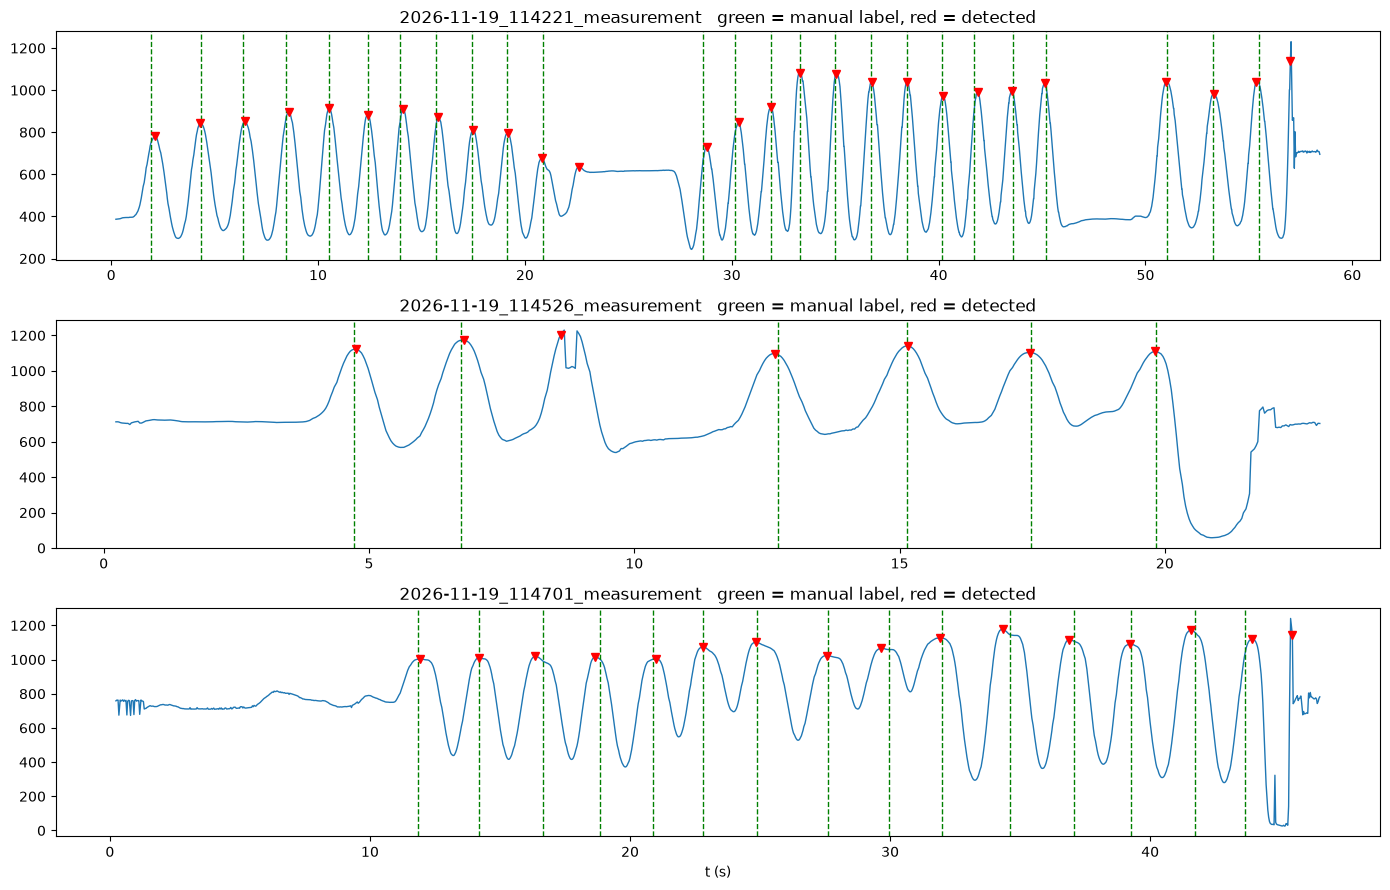

In [3]:
def detect_pushes(t, x, fps=30):
    peaks, _ = find_peaks(savgol_filter(x, 9, 2), prominence=150, distance=fps)
    return t[peaks]

rows = []
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for ax, name in zip(axes, LABELLED):
    video = pd.read_csv(ROOT / "analyses" / name / "tracking.csv").dropna(subset=["x"])
    markers = json.loads((ROOT / "analyses" / name / "markers.json").read_text())
    labels = np.array([m["t"] for m in markers if m.get("kind") == "push"])
    found = detect_pushes(video.t.to_numpy(), video.x.to_numpy())

    matched = [np.abs(found - l).min() < 0.3 for l in labels]
    extra = [np.abs(labels - f).min() >= 0.3 for f in found]
    rows.append({"recording": name, "labels": len(labels), "matched": sum(matched), "extra": sum(extra)})

    ax.plot(video.t, video.x, lw=1)
    for l in labels:
        ax.axvline(l, color="g", ls="--", lw=1)
    ax.plot(found, np.interp(found, video.t, video.x), "rv")
    ax.set_title(f"{name}   green = manual label, red = detected")
axes[-1].set_xlabel("t (s)")
plt.tight_layout()
pd.DataFrame(rows)

**Detected vs manual labels**

- all 46 manual labels are found
- 4 extra detections in total: tracking jumps of `x` or small movements at the end of a recording

"Push = peak of the position" reproduces the manual labels. The extras are the weak point of using the
video alone; the IMU can rule them out, because the sled did not really move there.

## 3. Check with the IMU: the pause at each push

At a push the sled is almost still for a short time. "Almost still" = |speed| below 10 % of the largest
speed in that recording; being relative, this works the same for px/s and m/s.

- video speed: derivative of the smoothed `x` (px/s)
- IMU speed: `v` from `analyse_start`, with the same high-pass as in step 1 (drift removed)

For every push found in the video we take the pause (±0.6 s around it) in both signals and compare three
candidate push moments: **stop** (start of the pause), **middle**, **go** (end of the pause, sled moves back).

IMU - video (ms) for each candidate moment:
recording  push (s)  pause (ms)  stop  middle  go
   120403      6.26         591    74      45  16
   120403      8.96         542    16      12   7
   120403     11.44         370     6     -30 -65
   120443      6.41         607    43      15 -14
   120443      9.20         670    58      23 -12
   120443     11.76         429    47       0 -48

mean |IMU - video| (ms):
stop      41.0
middle    21.0
go        27.0


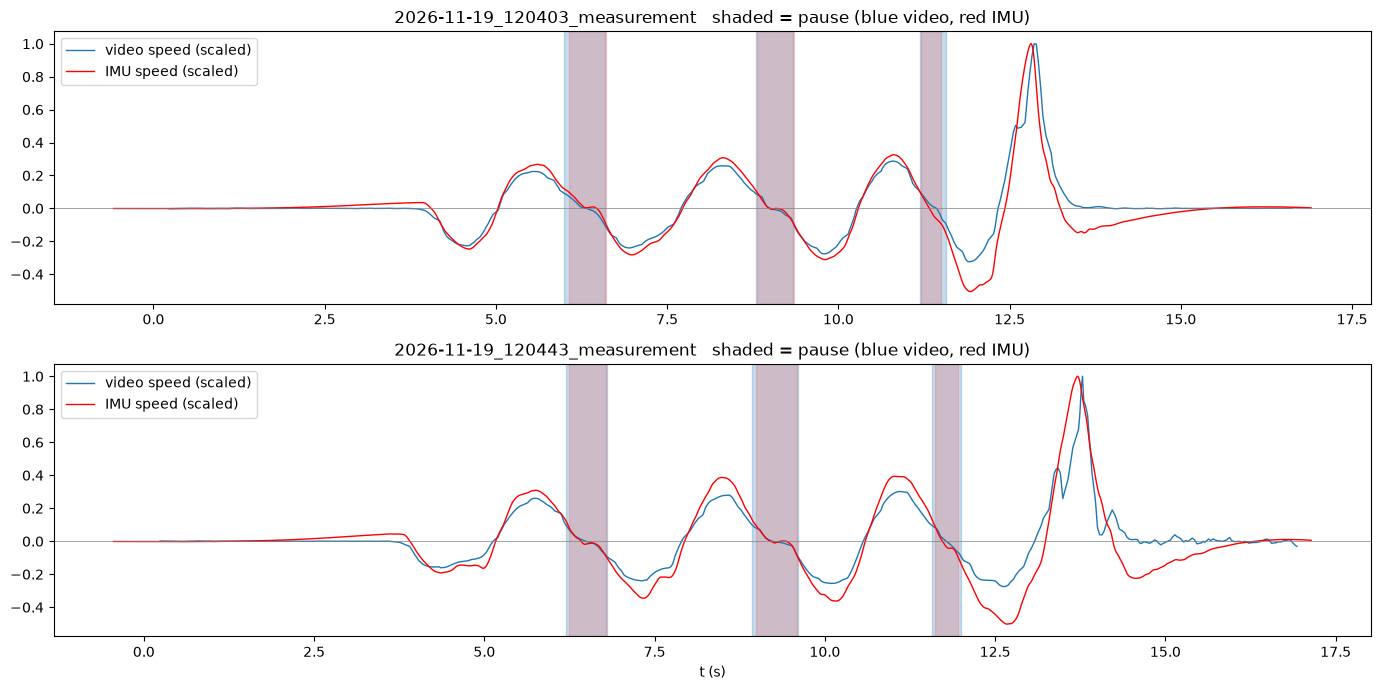

In [4]:
def pause(t, speed, t_push):
    still = np.abs(speed) < 0.1 * np.abs(speed).max()
    in_pause = t[still & (np.abs(t - t_push) < 0.6)]
    return in_pause.min(), in_pause.max()

rows = []
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, name in zip(axes, WITH_IMU):
    video, imu = data[name]
    t_video, t_imu = video.t.to_numpy(), imu.t.to_numpy()
    speed_video = savgol_filter(video.x.to_numpy(), 9, 2, deriv=1) * 30   # px per frame -> px/s
    speed_imu = filtfilt(hp_b, hp_a, imu.v.to_numpy())

    for push in detect_pushes(t_video, video.x.to_numpy()):
        v_start, v_end = pause(t_video, speed_video, push)
        i_start, i_end = pause(t_imu, speed_imu, push)
        rows.append({"recording": name[-18:-12], "push (s)": round(push, 2),
                     "pause (ms)": round(1000 * (v_end - v_start)),
                     "stop": round(1000 * (i_start - v_start)),
                     "middle": round(1000 * ((i_start + i_end) / 2 - (v_start + v_end) / 2)),
                     "go": round(1000 * (i_end - v_end))})
        ax.axvspan(v_start, v_end, color="tab:blue", alpha=0.25)
        ax.axvspan(i_start, i_end, color="red", alpha=0.15)

    ax.plot(t_video, speed_video / np.abs(speed_video).max(), lw=1, label="video speed (scaled)")
    ax.plot(t_imu, speed_imu / np.abs(speed_imu).max(), "r", lw=1, label="IMU speed (scaled)")
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_title(f"{name}   shaded = pause (blue video, red IMU)"); ax.legend(loc="upper left")
axes[-1].set_xlabel("t (s)")
plt.tight_layout()

pauses = pd.DataFrame(rows)
print("IMU - video (ms) for each candidate moment:")
print(pauses.to_string(index=False))
print("\nmean |IMU - video| (ms):")
print(pauses[["stop", "middle", "go"]].abs().mean().round().to_string())

**Pause: video vs IMU**

- scaled to the same height, video and IMU speed are almost the same curve, and the pauses overlap
- the pause lasts 0.4–0.7 s, so the choice of moment moves the push time by up to ±0.3 s
- mean |IMU − video|: **middle 21 ms**, go 27 ms, stop 41 ms
- at "stop" the IMU is always later: its speed falls more smoothly and crosses the threshold later

The middle of the pause is the moment that video and IMU measure most consistently.

## Conclusion

- **Sync** without camera calibration works: IMU +33 ms, r ≈ 0.99.
- **Push = peak of the video position** finds all 46 manual labels (4 extras from tracking errors).
- **Video and IMU agree** on the pause at each push; its **middle** is the most consistent push moment
  (21 ms mean difference, below one video frame).

Limits: 6 pushes in 2 recordings for the IMU check, and no recording has both IMU and manual labels.
Which moment of the pause should count as "the push" is still a team / coach decision; the middle is
the most reliable to measure.